### 1. Import Libraries and Load MNIST Dataset
We will use TensorFlow and Keras to import and prepare our data. The original LeNet-5 architecture expects 32x32 pixel inputs, so we will pad our 28x28 MNIST images to match.

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np

# Load MNIST dataset
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Reshape to (num_samples, 28, 28, 1) and normalize pixels to [0, 1]
x_train = x_train.reshape(-1, 28, 28, 1).astype('float32') / 255.0
x_test = x_test.reshape(-1, 28, 28, 1).astype('float32') / 255.0

# Pad images from 28x28 to 32x32 to match LeNet-5 structure
x_train = np.pad(x_train, ((0,0), (2,2), (2,2), (0,0)), 'constant')
x_test = np.pad(x_test, ((0,0), (2,2), (2,2), (0,0)), 'constant')

print(f"Training data shape: {x_train.shape}")
print(f"Testing data shape: {x_test.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 32, 32, 1)
Testing data shape: (10000, 32, 32, 1)


### 2. Define the LeNet-5 Architecture
We will build the Sequential network using the exact layers of LeNet-5: Convolutional layers with tanh activation, average pooling layers, and final fully connected dense layers.

In [2]:
def build_lenet5():
    model = models.Sequential([
        # C1: Convolutional layer (6 filters of 5x5, tanh activation)
        layers.Conv2D(6, kernel_size=(5, 5), activation='tanh', input_shape=(32, 32, 1)),

        # S2: Average Pooling layer (2x2, stride 2)
        layers.AveragePooling2D(pool_size=(2, 2), strides=2),

        # C3: Convolutional layer (16 filters of 5x5, tanh activation)
        layers.Conv2D(16, kernel_size=(5, 5), activation='tanh'),

        # S4: Average Pooling layer (2x2, stride 2)
        layers.AveragePooling2D(pool_size=(2, 2), strides=2),

        # C5: Convolutional layer (120 filters of 5x5, tanh activation)
        layers.Conv2D(120, kernel_size=(5, 5), activation='tanh'),

        # Flattening to transition to Dense layers
        layers.Flatten(),

        # F6: Fully Connected layer (84 units, tanh activation)
        layers.Dense(84, activation='tanh'),

        # Output layer: 10 outputs with softmax for classification (digits 0-9)
        layers.Dense(10, activation='softmax')
    ])
    return model

model = build_lenet5()
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

### 3. Compile and Train the Model
We compile with the Adam optimizer and fit the training data.

In [3]:
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history = model.fit(x_train, y_train, epochs=10, batch_size=64, validation_split=0.1)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 34s 38ms/step - accuracy: 0.9185 - loss: 0.2734 - val_accuracy: 0.9658 - val_loss: 0.1170
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 30s 36ms/step - accuracy: 0.9691 - loss: 0.0998 - val_accuracy: 0.9792 - val_loss: 0.0762
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.9794 - loss: 0.0661 - val_accuracy: 0.9780 - val_loss: 0.0707
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 32s 37ms/step - accuracy: 0.9844 - loss: 0.0500 - val_accuracy: 0.9840 - val_loss: 0.0582
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 30s 36ms/step - accuracy: 0.9870 - loss: 0.0399 - val_accuracy: 0.9828 - val_loss: 0.0590
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.9899 - loss: 0.0318 - val_accuracy: 0.9860 - val_loss: 0.0537
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 30s 36ms/step - accuracy: 0.9907 - loss: 0.0281 - val_accuracy: 0.9867 - val_loss: 0.0502
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 32s 38ms/step - accuracy: 0.9932 - loss: 0.0213 - 

### 4. Model Evaluation
Now we will evaluate the model's accuracy on the test set and plot the loss and accuracy metrics.

313/313 - 2s - 7ms/step - accuracy: 0.9845 - loss: 0.0507

Test accuracy: 0.9845


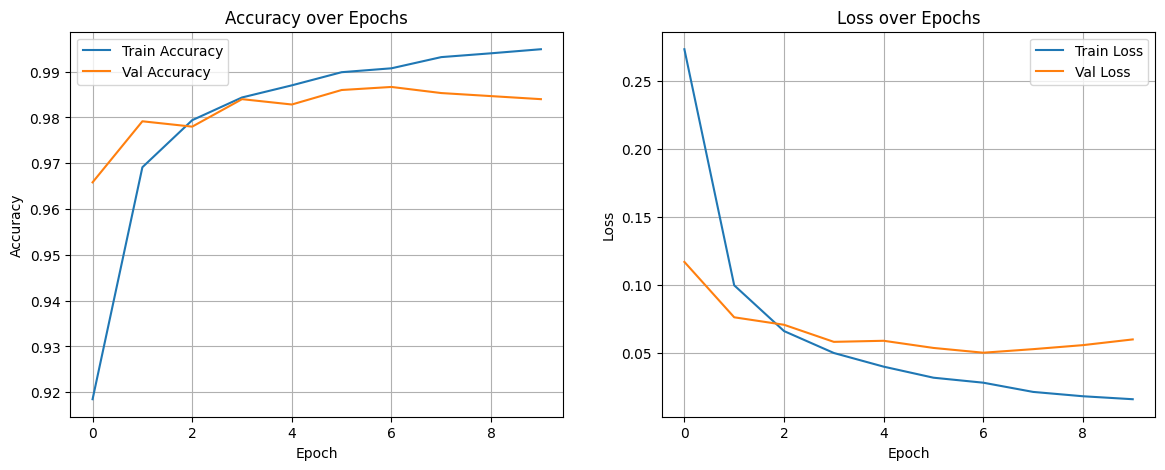

In [4]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nTest accuracy: {test_acc:.4f}")

# Plot learning results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train Accuracy')
ax1.plot(history.history['val_accuracy'], label='Val Accuracy')
ax1.set_title('Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()
ax1.grid(True)

# Loss plot
ax2.plot(history.history['loss'], label='Train Loss')
ax2.plot(history.history['val_loss'], label='Val Loss')
ax2.set_title('Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()
ax2.grid(True)

plt.show()